# Central Limit Theorem: Animated by sample Size

## The magic of CLT
No matter how weird the distribution looks, the **sample distribution of the mean** becomes Normal as sample size increases.

We'll prove this visually with:
1. uniform (flat)
2. Exponential (Skewed)
3. Bimodal (two peaks)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, clear_output
import time

np.random.seed(42)

def standard_error(sample_std, n):
    if n<=0:
        raise ValueError("Sample size must be positive")
    return sample_std/np.sqrt(n)

def confidence_interval(sample_mean, se, confidence=0.95):
    # se : standard error
    z = stats.norm.ppf((1+confidence)/2)
    margin = z*se
    return (sample_mean-margin, sample_mean+margin)

def test_standard_error():
    # SE of sigma=10, n=100 should be 1
    assert np.isclose(standard_error(10,100),1.0)
    # SE of sigma=10, n=25 should be 2
    assert np.isclose(standard_error(10,25),2.0)
    # SE  gets higher with high sqrt(n)
    assert standard_error(10,100)<standard_error(10,25)
    print("standard_error: all tests passed!")

def test_confidence_interval():
    # with mean =1, se=1, 95% CI should be approx (-1.96, 1.96)
    lo, hi = confidence_interval(0,1,0.95)
    assert np.isclose(lo, -1.96, atol=0.01)
    assert np.isclose(hi, 1.96, atol=0.01)
    # CI should be symmetric around mean
    lo, hi = confidence_interval(5,1,0.95)
    assert np.isclose((lo+hi)/2, 5)
    # wider CI for higher confidence
    lo_95, hi_95 = confidence_interval(0,1,0.95)
    lo_99, hi_99 = confidence_interval(0,1,0.99)
    assert (hi_99-lo_99) > (hi_95-lo_95)
    print("confidence_interval: all tests passed!")

test_standard_error()
test_confidence_interval()
    
    

standard_error: all tests passed!
confidence_interval: all tests passed!


## Distribution Generators
three deliberately non-normal distributions to prove CLT works on anything

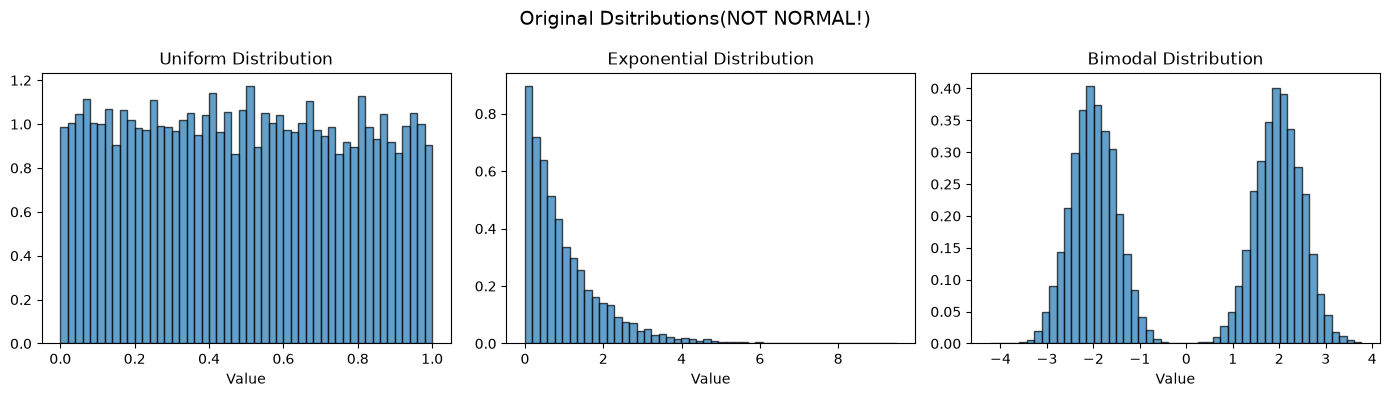

In [2]:
def generate_samples(dist_type, size):
    if dist_type == 'uniform':
        return np.random.uniform(0,1, size)
    if dist_type == 'exponential':
        return np.random.exponential(1, size)
    if dist_type == 'bimodal':
        mix = np.random.choice([0,1], size=size, p=[0.5,0.5])
        return np.where(mix==0,
                        np.random.normal(-2,0.5, size),
                        np.random.normal(2,0.5, size))
    else:
        raise ValueError(f"Unknown Distribution: {dist_type}")

## showing what each distribution look like
fig, axes = plt.subplots(1,3, figsize=(14,4))
for ax, dist in zip(axes,['uniform', 'exponential', 'bimodal']):
    samples = generate_samples(dist, 10000)
    ax.hist(samples, bins=50, density=True, alpha=0.7, edgecolor='black')
    ax.set_title(f'{dist.capitalize()} Distribution')
    ax.set_xlabel('Value')
plt.suptitle('Original Dsitributions(NOT NORMAL!)', fontsize=14)
plt.tight_layout()
plt.show()        

## CLT Animation: Watch Normality Emerge!
As sample size increases, the distributio of sample means becomes Normal

In [3]:
def animate_clt(dist_type, sample_sizes=[1,2,5,10,30,100], n_simulations=2000):
    fig, axes = plt.subplots(2, 3, figsize=(14,8))
    axes = axes.flatten()

    for idx, n in enumerate(sample_sizes):
        sample_means = []
        for _ in range(n_simulations):
            sample = generate_samples(dist_type,n)
            sample_means.append(np.mean(sample))
        sample_means = np.array(sample_means)

        # plot histogram of sample means
        ax = axes[idx]
        ax.hist(sample_means, bins=40, density=True, alpha=0.7, color='steelblue', edgecolor='black')

        # overlay theoretical normal
        mu = np.mean(sample_means)
        sigma = np.std(sample_means)
        x = np.linspace(mu-4*sigma, mu+4*sigma, 100)
        ax.plot(x, stats.norm.pdf(x, mu, sigma), 'r-', lw=2, label='Normal Fit')

        # calculate and display SE
        se = standard_error(np.std(generate_samples(dist_type, 10000)), n)

        ax.set_title(f'n={n}\nSE~{se:.3f}', fontsize=12)
        ax.set_xlabel('Sample Mean')
        if idx == 0:
            ax.legend()

    plt.suptitle(f'CLT in Action: {dist_type.capitalize()} Distribution\n'
                 f'({n_simulations} simulations per sample size)', fontsize=14)
    plt.tight_layout()
    plt.show()


UNIFORM Distribution


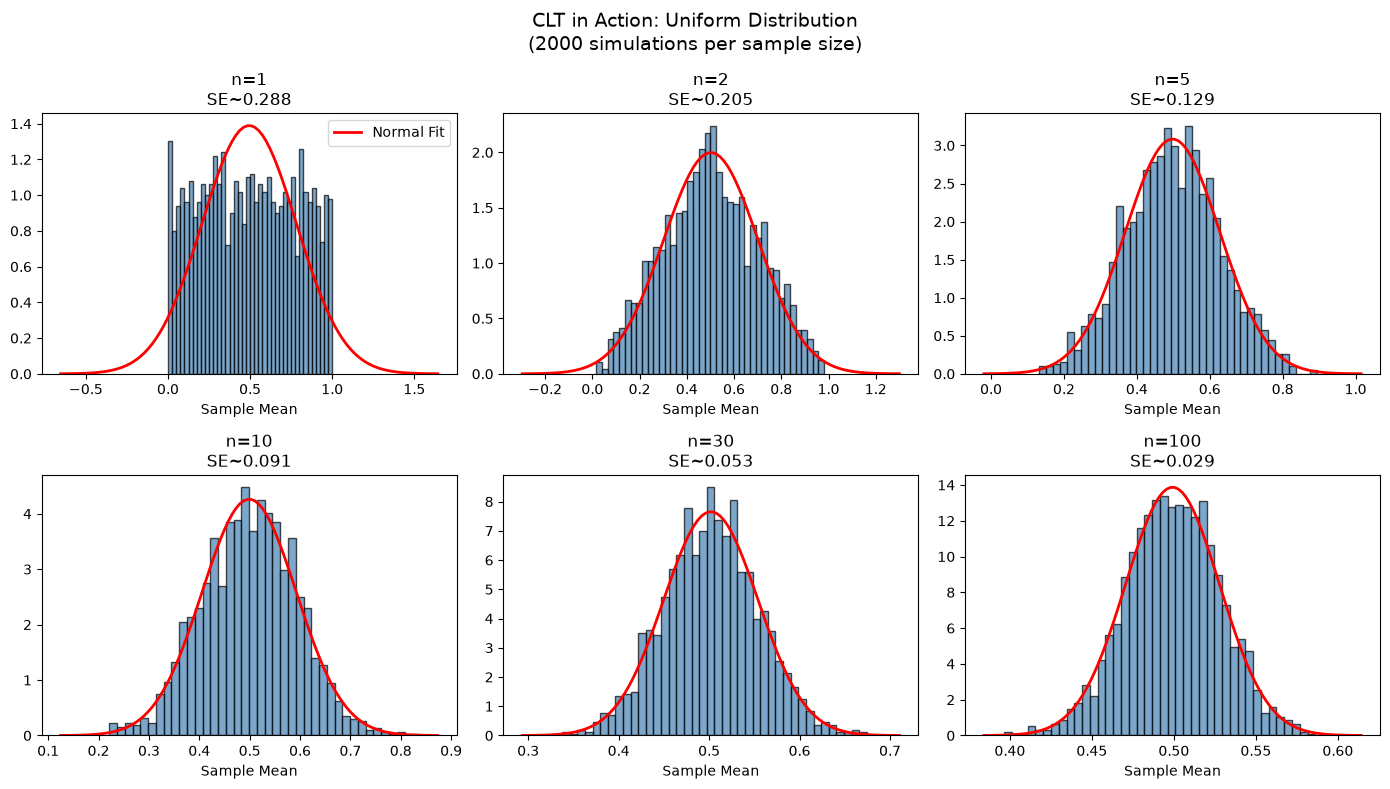

EXPONENTIAL Distribution


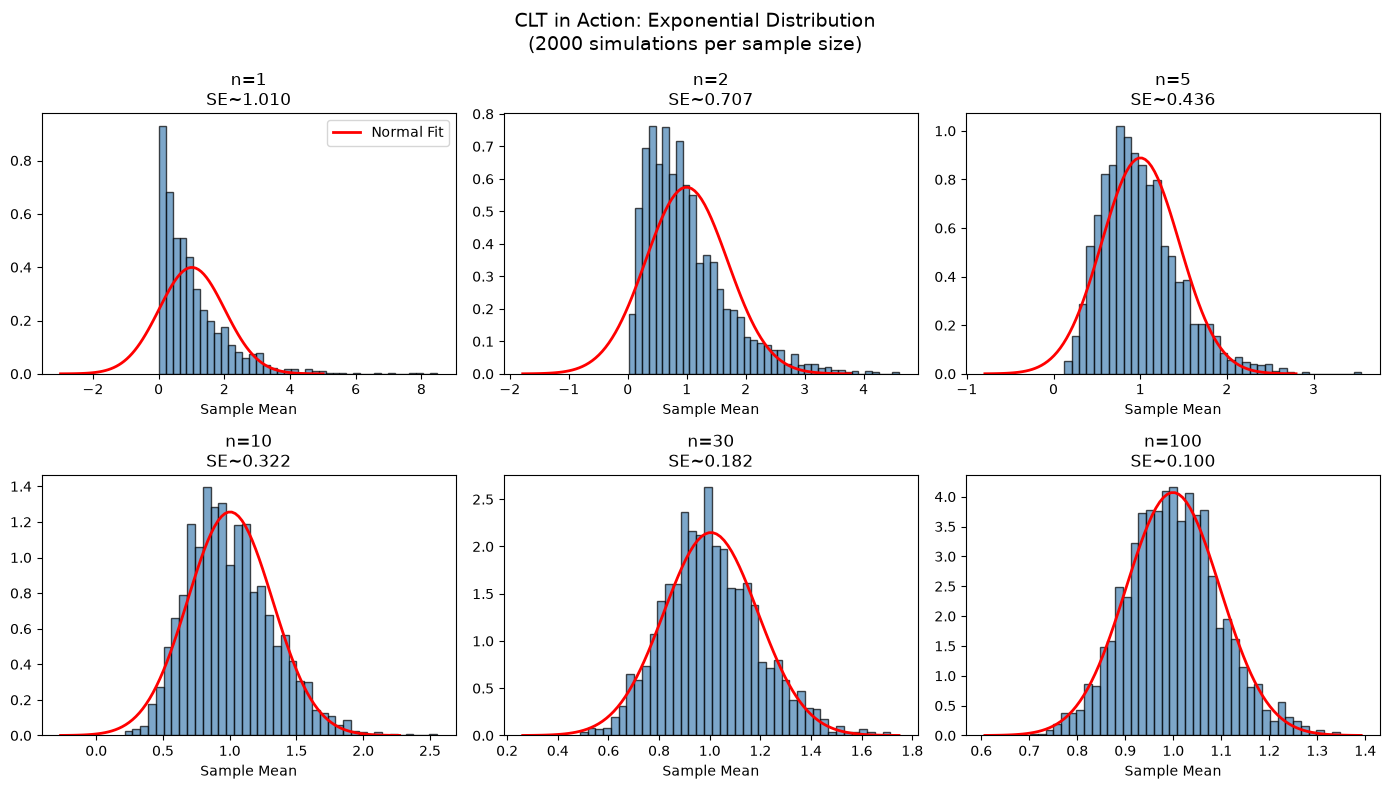

BIMODAL Distribution


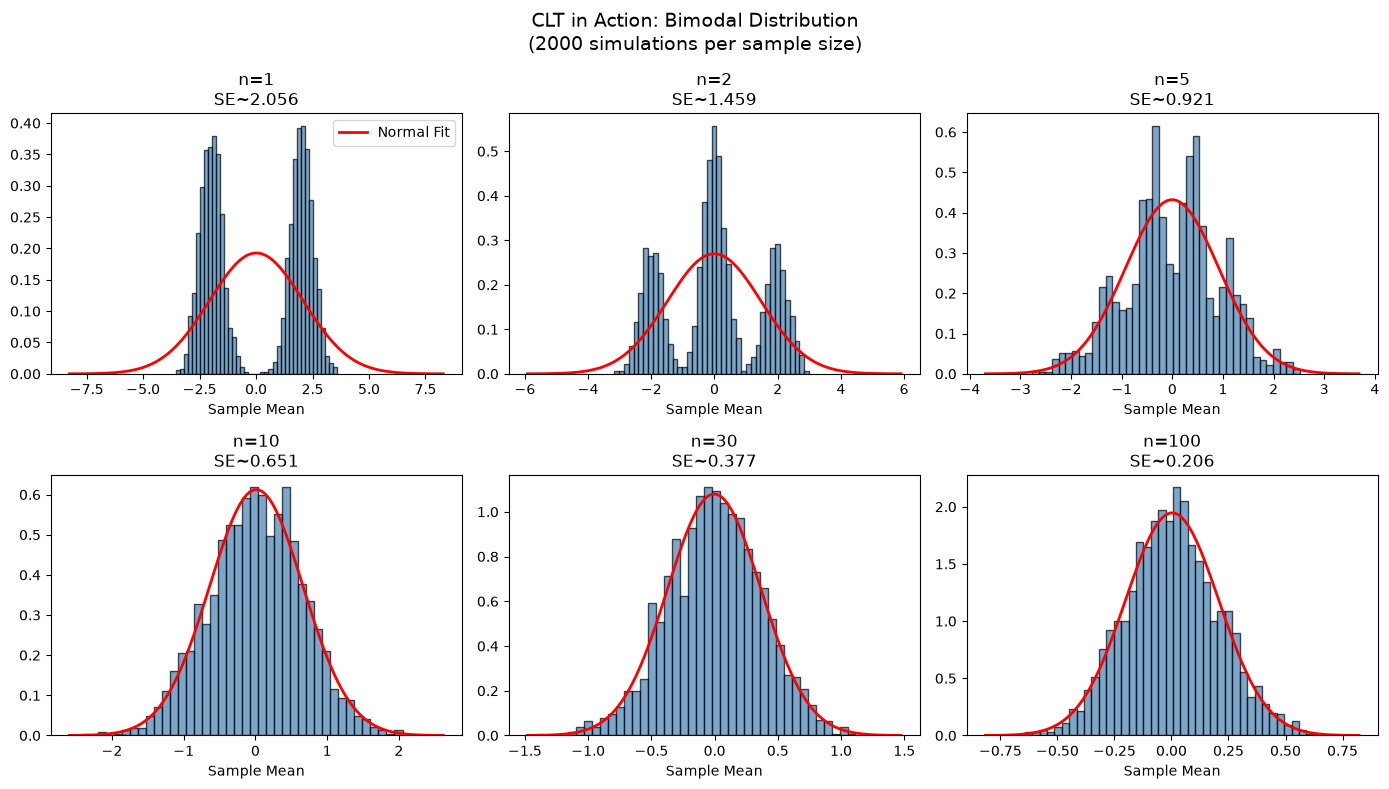

In [7]:
for dist in ['uniform', 'exponential', 'bimodal']:
    print('='*50)
    print(f"{dist.upper()} Distribution")
    print('='*50)
    animate_clt(dist)

## SE Shrinks with squared n - Visual Proof

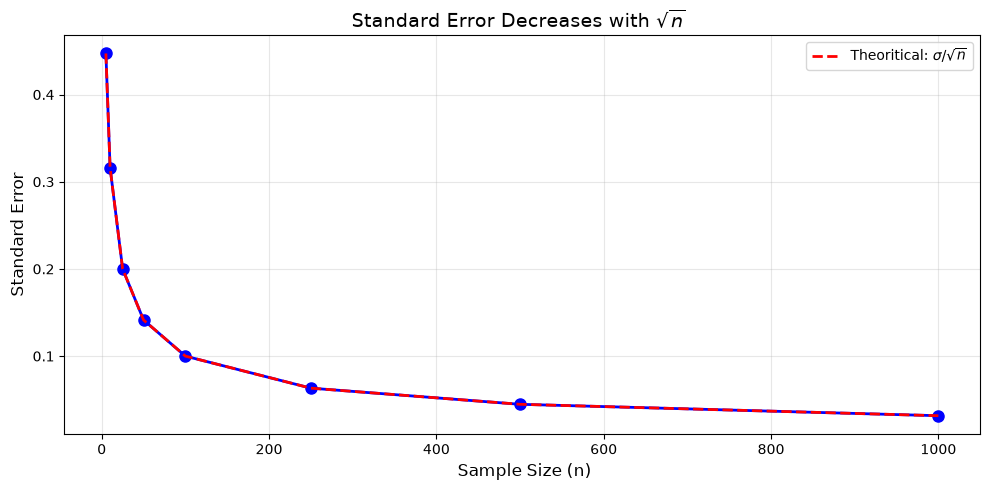

Key Insight: To halve SE, we must quadruple sample size
n= 100: SE = 0.100
n= 400: SE = 0.050


In [8]:
sample_sizes = np.array([5, 10, 25, 50, 100, 250, 500, 1000])
sigma= 1.0

se_values = [standard_error(sigma, n) for n in sample_sizes]

plt.figure(figsize=(10,5))
plt.plot(sample_sizes, se_values, 'bo-', markersize=8, lw=2)
plt.plot(sample_sizes, sigma/np.sqrt(sample_sizes), 'r--', lw=2, label=r'Theoritical: $\sigma / \sqrt{n}$')
plt.xlabel(' Sample Size (n)', fontsize=12)
plt.ylabel('Standard Error', fontsize=12)
plt.title(r'Standard Error Decreases with $\sqrt{n}$ ', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Key Insight: To halve SE, we must quadruple sample size")
print(f"n= 100: SE = {standard_error(1, 100):.3f}")
print(f"n= 400: SE = {standard_error(1, 400):.3f}")

## Confidence Interval Coverage Test
If our CI is correct, ~95% of intervals should contain the true mean

In [9]:
def test_ci_coverage(true_mean, true_std, n, confidence=0.95, n_trials=1000):
    hits = 0
    for _ in range(n_trials):
        sample = np.random.normal(true_mean, true_std, n)
        sample_mean = np.mean(sample)
        se = standard_error(np.std(sample, ddof=1), n)
        lo, hi = confidence_interval(sample_mean, se, confidence)
        if lo <= true_mean <= hi:
            hits +=1

    coverage = hits / n_trials
    return coverage

# test with known parameters
true_mu, true_sigma = 50, 10

print("CI coverage Test (should be ~95%)")
print('-'*40)
for n in [10, 30, 100, 500]:
    coverage = test_ci_coverage(true_mu, true_sigma, n)
    status = "Good" if 0.93 <= coverage <= 0.97 else "Not Good!"
    print(f"n={n:3d}: {coverage:.1%} coverage {status}")

CI coverage Test (should be ~95%)
----------------------------------------
n= 10: 91.5% coverage Not Good!
n= 30: 92.8% coverage Not Good!
n=100: 95.3% coverage Good
n=500: 95.2% coverage Good


## key Takeways
1. **CLT is universal**: Works for any distribution with finite variance
2. **Sample size matters**: n = 30 is often "good enough" for normality
3. **SE = $\sigma / \sqrt{n}$**: Uncertainty shrinks slowly - need 4x samples for 2x precision
4. **95% CI**: Roughly mean +/- 2xSE